In [2]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, Sequential


In [3]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    device = "/GPU:0"
    print(f"Using GPU: {gpus[0]}")
else:
    device = "/CPU:0"
    print("No GPU detected. Using CPU.")


Using GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


I0000 00:00:1791125565.441671      89 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791125565.489198      89 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791125565.491938      89 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355


Hyperparameters

In [4]:
IMG_SIZE = 64
CHANNELS = 3 
BATCH_SIZE = 32
LR = 0.001
EPOCHS = 20  # Set to a low number for convenience. Change as needed.

Data location

In [5]:
# make sure the data is downloaded,  extracted and split into train and test - if not please use the 01 notebook.
train_dir = Path("./data/train")
val_dir = Path("./data/test")

Classes

In [6]:
class_names = sorted(
    d.name for d in train_dir.iterdir()
    if d.is_dir()
)

class_to_index = {
    name: i for i, name in enumerate(class_names)
}

num_classes = len(class_names)

print(class_names)
print(class_to_index)

['class_0_non_agri', 'class_1_agri']
{'class_0_non_agri': 0, 'class_1_agri': 1}


At this point we could create a custom data generator to yield batch after batch as follows:

```python
def custom_data_generator(image_paths, labels, batch_size, target_size=(64, 64)):
    """A custom data generator to feed a Keras model."""
    num_samples = len(image_paths)
    while True: 
        # Shuffle data at the beginning of each epoch
        indices = np.arange(num_samples)
        np.random.shuffle(indices)
        shuffled_paths = np.array(image_paths)[indices]
        shuffled_labels = np.array(labels)[indices]
        
        # Generate batch data
        for offset in range(0, num_samples, batch_size):
            batch_paths = shuffled_paths[offset:offset+batch_size]
            batch_labels = shuffled_labels[offset:offset+batch_size]
            
            # Load and preprocess images from the batch
            batch_images = []
            for path in batch_paths:
                img = tf.keras.utils.load_img(path, target_size=target_size)
                img_array = tf.keras.utils.img_to_array(img)
                batch_images.append(img_array)
            
            # Normalize and yield the batch data
            yield np.array(batch_images) / 255.0, np.array(batch_labels)

image_extensions = {".jpg", ".jpeg" }

train_files = [
    (str(f), class_to_index[f.parent.name])
    for f in train_dir.rglob("*")
    if f.is_file() and f.suffix.lower() in image_extensions
]

train_paths = [path for path, label in train_files]
train_labels = [label for path, label in train_files]

gen = custom_data_generator(train_paths, train_labels, 5)
test = next(gen)
print(len(test),test[0].shape, test[1].shape)
```

However we have no special operations to perform and it is more convenient to use the tf.data.Dataset tools.

## Create the datasets from folders of images

Keras offers a handy function to turn folders to datasets directly. Below we have already set up separate validation folder, however Keras can also split a single folder at this stage if that was needed, as follows:

```python
train_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    labels='inferred',          # Labels are generated from directory structure
    label_mode='int',           # Labels are encoded as integers (0, 1, ...)
    validation_split=0.2,       # Reserve 20% of images for validation
    subset='training',          # This is the training set
    seed=1337,                  # Shuffle seed for reproducible splits
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    labels='inferred',
    label_mode='int',
    validation_split=0.2,
    subset='validation',
    seed=1337,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

```

In [9]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(64, 64),
    batch_size=32,
    label_mode="int",
    shuffle=True,
)

Found 5600 files belonging to 2 classes.


In [8]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(64, 64),
    batch_size=32,
    label_mode="int",
    shuffle=False,
)

Found 400 files belonging to 2 classes.


### Performance set up

The dedicated utility, `tf.data.Dataset`, can be chained with various methods to create a highly performant pipeline. 
- **`.map(function)`:** Applies a given function to every element of the dataset. Here, it is used to apply data augmentation layers. TensorFlow can automatically parallelize this operation.
- **`.cache()`:** Caches the dataset in memory after it's loaded from disk during the first epoch. For subsequent epochs, data will be read from the faster memory cache, significantly speeding up training. This is **only feasible if** the dataset fits in RAM.
- **`.prefetch(buffer_size)`:** It allows the data preprocessing (done on the CPU) to happen in parallel with the model training (done on the GPU). While the GPU is busy with the current batch, the CPU is already preparing the next batch. This overlapping of tasks prevents the GPU from sitting idle and waiting for data, a phenomenon known as an I/O bottleneck.
- **`AUTOTUNE`** lets TensorFlow dynamically decide the optimal buffer size for your computer.

**Important point:** If you cache before the data augmentation, you will not get the changes every epoch as intented! You must first cache and then augment the cached images every time.

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, Model


# ---------------------------------------------------------
# 1. Patch extraction + linear patch embedding
# ---------------------------------------------------------
class PatchEmbedding(layers.Layer):
    def __init__(self, image_size=64, patch_size=8, embed_dim=64, **kwargs):
        super().__init__(**kwargs)

        self.image_size = image_size
        self.patch_size = patch_size
        self.embed_dim = embed_dim

        self.num_patches = (image_size // patch_size) ** 2

        # Extract non-overlapping patches
        self.projection = layers.Conv2D(
            filters=embed_dim,
            kernel_size=patch_size,
            strides=patch_size,
            padding="valid"
        )

    def call(self, images):
        x = self.projection(images)

        # (batch, 8, 8, embed_dim)
        # -> (batch, 64, embed_dim)
        x = tf.reshape(
            x,
            [tf.shape(x)[0], self.num_patches, self.embed_dim]
        )

        return x

    def get_config(self):
        config = super().get_config()
        config.update({
            "image_size": self.image_size,
            "patch_size": self.patch_size,
            "embed_dim": self.embed_dim,
        })
        return config


# ---------------------------------------------------------
# 2. Learnable positional embedding
# ---------------------------------------------------------
class AddPositionEmbedding(layers.Layer):
    def __init__(self, num_patches, embed_dim, **kwargs):
        super().__init__(**kwargs)

        self.num_patches = num_patches
        self.embed_dim = embed_dim

        self.pos = self.add_weight(
            name="pos_embedding",
            shape=(1, num_patches, embed_dim),
            initializer="random_normal",
            trainable=True
        )

    def call(self, tokens):
        return tokens + self.pos

    def get_config(self):
        config = super().get_config()
        config.update({
            "num_patches": self.num_patches,
            "embed_dim": self.embed_dim,
        })
        return config


# ---------------------------------------------------------
# 3. Small Transformer encoder block
# ---------------------------------------------------------
class TransformerBlock(layers.Layer):
    def __init__(
        self,
        embed_dim,
        num_heads=4,
        mlp_dim=128,
        dropout=0.1,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.mlp_dim = mlp_dim
        self.dropout = dropout

        # IMPORTANT:
        # key_dim is the dimension PER attention head.
        self.mha = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout
        )

        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)

        self.mlp = tf.keras.Sequential([
            layers.Dense(mlp_dim, activation="gelu"),
            layers.Dropout(dropout),
            layers.Dense(embed_dim),
            layers.Dropout(dropout),
        ])

    def call(self, x):
        # Self-attention + residual connection
        attention_output = self.mha(x, x)
        x = self.norm1(x + attention_output)

        # MLP + residual connection
        mlp_output = self.mlp(x)
        x = self.norm2(x + mlp_output)

        return x

    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "mlp_dim": self.mlp_dim,
            "dropout": self.dropout,
        })
        return config


# ---------------------------------------------------------
# 4. Build the small pure ViT
# ---------------------------------------------------------
def build_small_vit(
    image_size=64,
    patch_size=8,
    embed_dim=64,
    num_heads=4,
    mlp_dim=128,
    num_transformer_layers=2,
    dropout=0.1,
    num_classes=2
):

    num_patches = (image_size // patch_size) ** 2

    inputs = layers.Input(
        shape=(image_size, image_size, CHANNELS)
    )

    # Image -> patch tokens
    x = PatchEmbedding(
        image_size=image_size,
        patch_size=patch_size,
        embed_dim=embed_dim
    )(inputs)

    # Add positional information
    x = AddPositionEmbedding(
        num_patches=num_patches,
        embed_dim=embed_dim
    )(x)

    # Transformer encoder
    for _ in range(num_transformer_layers):
        x = TransformerBlock(
            embed_dim=embed_dim,
            num_heads=num_heads,
            mlp_dim=mlp_dim,
            dropout=dropout
        )(x)

    # Pool the token sequence
    x = layers.GlobalAveragePooling1D()(x)

    # Classification head
    x = layers.Dropout(dropout)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return Model(inputs, outputs, name="small_vit")

In [12]:
vit_model = build_small_vit(
    image_size=IMG_SIZE,
    patch_size=8,
    embed_dim=64,
    num_heads=4,
    mlp_dim=128,
    num_transformer_layers=2,
    dropout=0.1,
    num_classes=num_classes
)

vit_model.summary()

Model: "small_vit"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ patch_embedding                 │ (None, 64, 64)         │        12,352 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_position_embedding          │ (None, 64, 64)         │         4,096 │
│ (AddPositionEmbedding)          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 64, 64)         │        33,472 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 64, 64)         │        33,472 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,522 (326.26 KB)

 Trainable params: 83,522 (326.26 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
vit_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [16]:
history_vit = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30
)

Epoch 1/30


I0000 00:00:1791125889.431106     203 service.cc:146] XLA service 0x738a98009620 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791125889.431136     203 service.cc:154]   StreamExecutor device (0): NVIDIA GeForce GTX 1650, Compute Capability 7.5


 13/175 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.5304 - loss: 1.2251

I0000 00:00:1791125896.571293     203 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


175/175 ━━━━━━━━━━━━━━━━━━━━ 16s 29ms/step - accuracy: 0.6612 - loss: 0.6865 - val_accuracy: 0.8775 - val_loss: 0.2422
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9310 - loss: 0.1676 - val_accuracy: 0.9500 - val_loss: 0.1145
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9558 - loss: 0.1178 - val_accuracy: 0.9625 - val_loss: 0.1194
Epoch 4/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9490 - loss: 0.1312 - val_accuracy: 0.9475 - val_loss: 0.1364
Epoch 5/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9584 - loss: 0.1092 - val_accuracy: 0.9650 - val_loss: 0.0901
Epoch 6/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9563 - loss: 0.1095 - val_accuracy: 0.9725 - val_loss: 0.0786
Epoch 7/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9708 - loss: 0.0790 - val_accuracy: 0.9725 - val_loss: 0.0588
Epoch 8/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9736 - loss: 0.0695 - val_accuracy: 0.99

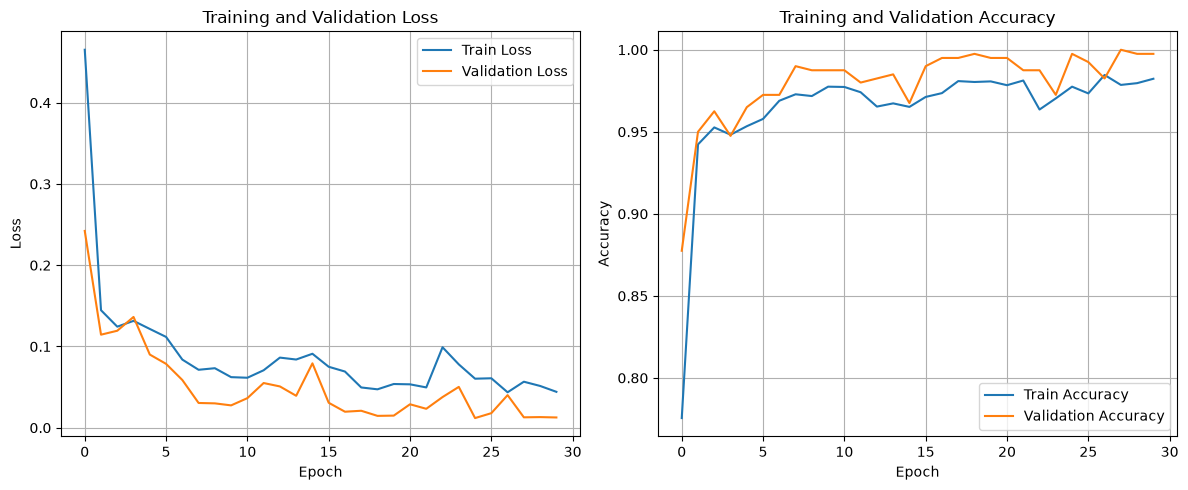

In [18]:
import matplotlib.pyplot as plt

# Plot loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_vit.history["loss"], label="Train Loss")
plt.plot(history_vit.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

# Plot accuracy
plt.subplot(1, 2, 2)
plt.plot(history_vit.history["accuracy"], label="Train Accuracy")
plt.plot(history_vit.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [22]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# ---------------------------------------------------------
# 1. Load pretrained CNN
# ---------------------------------------------------------

cnn = tf.keras.models.load_model(
    "ai_capstone_keras_best_model.model.keras"
)

# Freeze the pretrained CNN
cnn.trainable = False


# ---------------------------------------------------------
# 2. Create a new explicit input
# ---------------------------------------------------------

inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, CHANNELS)
)


# ---------------------------------------------------------
# 3. Pass the input through the pretrained CNN
# ---------------------------------------------------------

x = cnn(inputs)


# ---------------------------------------------------------
# 4. We DON'T want the CNN's final classifier.
#
# So instead, create a feature-extractor model
# from the CNN's input to max_pooling2d_7.
# ---------------------------------------------------------

feature_extractor = Model(
    inputs=cnn.layers[0].input,
    outputs=cnn.get_layer("max_pooling2d_7").output
)

feature_extractor.trainable = False

x = feature_extractor(inputs)


# ---------------------------------------------------------
# 5. Convert 4x4 feature map into 16 tokens
#
# (batch, 4, 4, 128)
#       ↓
# (batch, 16, 128)
# ---------------------------------------------------------

x = layers.Reshape((16, 128))(x)


# ---------------------------------------------------------
# 6. Positional embedding
# ---------------------------------------------------------

x = AddPositionEmbedding(
    num_patches=16,
    embed_dim=128
)(x)


# ---------------------------------------------------------
# 7. Transformer block
# ---------------------------------------------------------

x = TransformerBlock(
    embed_dim=128,
    num_heads=4,
    mlp_dim=256,
    dropout=0.1
)(x)


# ---------------------------------------------------------
# 8. Classification head
# ---------------------------------------------------------

x = layers.GlobalAveragePooling1D()(x)

x = layers.Dropout(0.1)(x)

outputs = layers.Dense(
    2,
    activation="softmax"
)(x)


# ---------------------------------------------------------
# 9. Build hybrid model
# ---------------------------------------------------------

hybrid_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="cnn_vit_hybrid"
)


# ---------------------------------------------------------
# 10. Compile
# ---------------------------------------------------------

hybrid_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


hybrid_model.summary()

Model: "cnn_vit_hybrid"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_90 (Functional)      │ (None, 4, 4, 128)      │        98,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 16, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_position_embedding_4        │ (None, 16, 128)        │         2,048 │
│ (AddPositionEmbedding)          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_5             │ (None, 16, 128)        │       132,480 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 233,186 (910.88 KB)

 Trainable params: 134,786 (526.51 KB)

 Non-trainable params: 98,400 (384.38 KB)

In [23]:
hybrid_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_hybrid = hybrid_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30
)

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.9783 - loss: 0.0362 - val_accuracy: 0.9975 - val_loss: 0.0082
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9982 - loss: 0.0043 - val_accuracy: 0.9950 - val_loss: 0.0141
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9976 - loss: 0.0059 - val_accuracy: 0.9950 - val_loss: 0.0212
Epoch 4/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9953 - loss: 0.0127 - val_accuracy: 0.9950 - val_loss: 0.0064
Epoch 5/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9967 - loss: 0.0088 - val_accuracy: 0.9925 - val_loss: 0.0186
Epoch 6/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9984 - loss: 0.0052 - val_accuracy: 0.9925 - val_loss: 0.0085
Epoch 7/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9978 - loss: 0.0046 - val_accuracy: 0.9950 - val_loss: 0.0070
Epoch 8/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9972 - loss: 0.0071 - val_acc

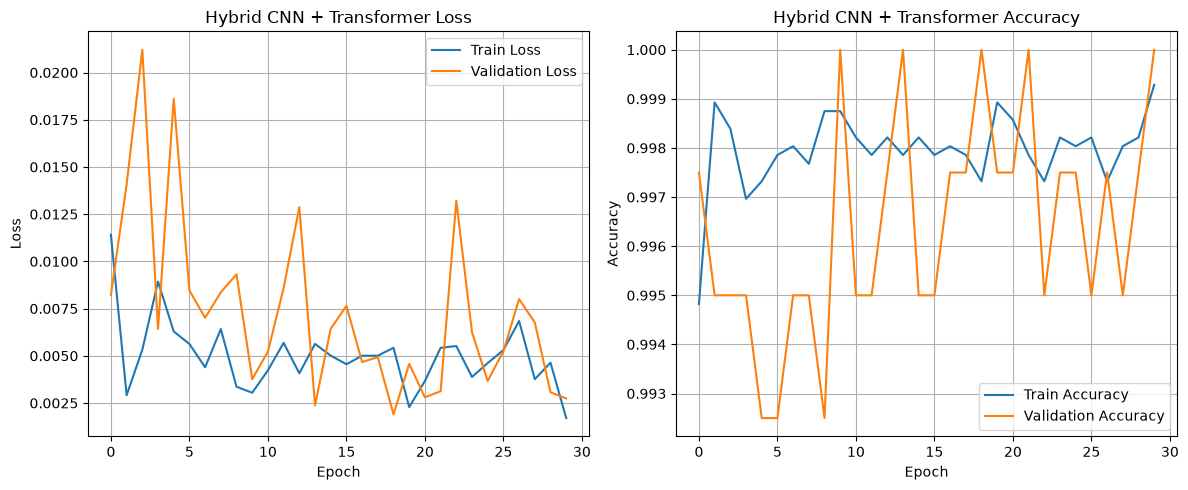

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_hybrid.history["loss"], label="Train Loss")
plt.plot(history_hybrid.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Hybrid CNN + Transformer Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_hybrid.history["accuracy"], label="Train Accuracy")
plt.plot(history_hybrid.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Hybrid CNN + Transformer Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [28]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# ---------------------------------------------------------
# Load pretrained CNN
# ---------------------------------------------------------

cnn = tf.keras.models.load_model(
    "ai_capstone_keras_best_model.model.keras"
)

# Freeze pretrained CNN
cnn.trainable = False


# ---------------------------------------------------------
# Create input
# ---------------------------------------------------------

inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, CHANNELS)
)


# ---------------------------------------------------------
# Feature extractor:
# keep only the first TWO CNN blocks
#
# Output:
# (batch, 16, 16, 32)
# ---------------------------------------------------------

feature_extractor = Model(
    inputs=cnn.layers[0].input,
    outputs=cnn.get_layer("max_pooling2d_5").output
)

feature_extractor.trainable = False

x = feature_extractor(inputs)


# ---------------------------------------------------------
# Convert feature map into tokens
#
# 16 × 16 = 256 tokens
# Each token has 32 features
#
# (batch, 16, 16, 32)
#       ↓
# (batch, 256, 32)
# ---------------------------------------------------------

x = layers.Reshape((256, 32))(x)


# ---------------------------------------------------------
# Positional embedding
# ---------------------------------------------------------

x = AddPositionEmbedding(
    num_patches=256,
    embed_dim=32
)(x)


# ---------------------------------------------------------
# Transformer block
# ---------------------------------------------------------

x = TransformerBlock(
    embed_dim=32,
    num_heads=4,
    mlp_dim=128,
    dropout=0.2
)(x)


# ---------------------------------------------------------
# Classification head
# ---------------------------------------------------------

x = layers.GlobalAveragePooling1D()(x)

x = layers.Dropout(0.1)(x)

outputs = layers.Dense(
    2,
    activation="softmax"
)(x)


# ---------------------------------------------------------
# Build model
# ---------------------------------------------------------

hybrid_half_CNN = Model(
    inputs=inputs,
    outputs=outputs,
    name="hybrid_half_CNN"
)


# ---------------------------------------------------------
# Check model
# ---------------------------------------------------------

hybrid_half_CNN.summary()

Model: "hybrid_half_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_136 (Functional)     │ (None, 16, 16, 32)     │         5,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_5 (Reshape)             │ (None, 256, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_position_embedding_6        │ (None, 256, 32)        │         8,192 │
│ (AddPositionEmbedding)          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_7             │ (None, 256, 32)        │        12,704 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_6      │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,242 (102.51 KB)

 Trainable params: 20,962 (81.88 KB)

 Non-trainable params: 5,280 (20.62 KB)

In [29]:
hybrid_half_CNN.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_half_CNN = hybrid_half_CNN.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30
)

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.9571 - loss: 0.1173 - val_accuracy: 0.9950 - val_loss: 0.0126
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9938 - loss: 0.0136 - val_accuracy: 0.9925 - val_loss: 0.0136
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9962 - loss: 0.0101 - val_accuracy: 0.9950 - val_loss: 0.0152
Epoch 4/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9971 - loss: 0.0082 - val_accuracy: 0.9925 - val_loss: 0.0211
Epoch 5/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9978 - loss: 0.0075 - val_accuracy: 0.9925 - val_loss: 0.0280
Epoch 6/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9973 - loss: 0.0079 - val_accuracy: 0.9925 - val_loss: 0.0305
Epoch 7/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9972 - loss: 0.0079 - val_accuracy: 0.9925 - val_loss: 0.0337
Epoch 8/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9981 - loss: 0.0048 - val_accu

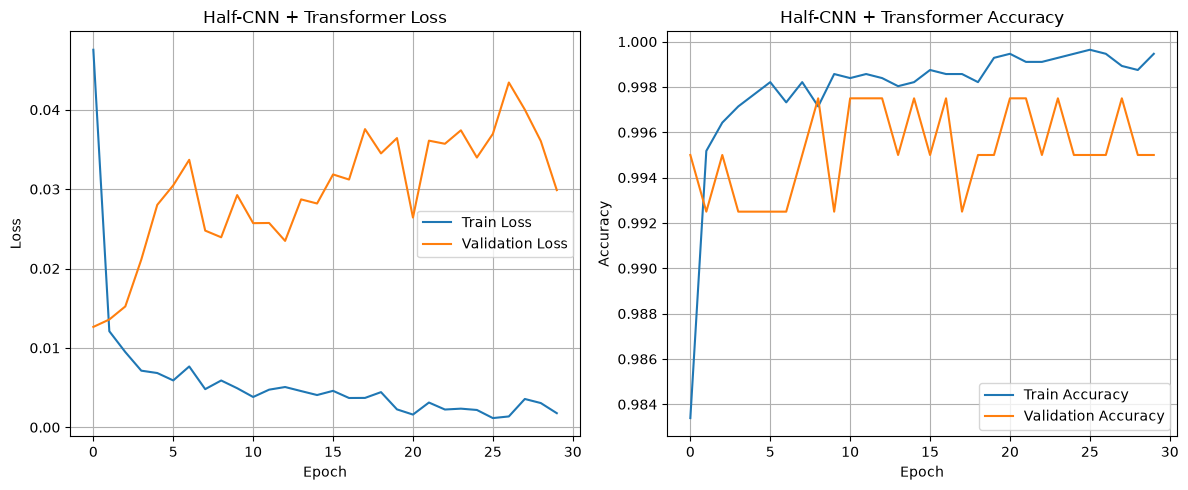

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(history_half_CNN.history["loss"], label="Train Loss")
plt.plot(history_half_CNN.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Half-CNN + Transformer Loss")
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(history_half_CNN.history["accuracy"], label="Train Accuracy")
plt.plot(history_half_CNN.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Half-CNN + Transformer Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# Get class names

misclassified_images = []
misclassified_true = []
misclassified_pred = []
misclassified_conf = []

# Go through the entire validation set
for images, labels in val_ds:
    predictions = hybrid_half_CNN.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)
    confidences = np.max(predictions, axis=1)

    for i in range(len(images)):
        if predicted_classes[i] != labels[i].numpy():
            misclassified_images.append(images[i].numpy())
            misclassified_true.append(labels[i].numpy())
            misclassified_pred.append(predicted_classes[i])
            misclassified_conf.append(confidences[i])

print(f"Misclassified images: {len(misclassified_images)}")

Misclassified images: 2


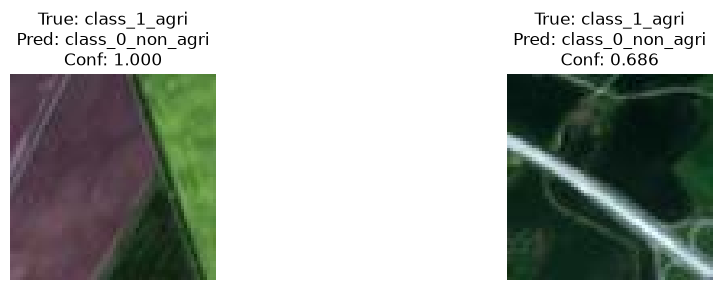

In [35]:
import math
import matplotlib.pyplot as plt

n = len(misclassified_images)

if n == 0:
    print("No misclassified images!")
else:
    cols = min(4, n)
    rows = math.ceil(n / cols)

    plt.figure(figsize=(12, 3 * rows))

    for i in range(n):
        ax = plt.subplot(rows, cols, i + 1)

        # Convert 0–255 float32 -> uint8
        image = np.clip(misclassified_images[i], 0, 255).astype(np.uint8)

        plt.imshow(image)

        plt.title(
            f"True: {class_names[misclassified_true[i]]}\n"
            f"Pred: {class_names[misclassified_pred[i]]}\n"
            f"Conf: {misclassified_conf[i]:.3f}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()